# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
# Static image export: kaleido 0.2.1 ships its own Chromium (works on Colab)
!pip install -q "plotly==5.24.1" "kaleido==0.2.1"

In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

import plotly.io as pio
pio.renderers.default = 'colab+plotly_mimetype+png'   # Colab + VS Code + static PNG for GitHub
pio.renderers['png'].width = 1100                      # wide enough for the insight titles

import os
os.makedirs('images', exist_ok=True)

def save_and_show(fig, name):
    """Save the figure as a PNG in images/ and display it."""
    fig.write_image(f'images/{name}.png', width=1100, height=fig.layout.height or 550, scale=2)
    fig.show()

# One CVD-safe palette for the whole notebook: grey = context, orange / blue = accents
ORANGE, BLUE, GREY, LGREY = '#E07B39', '#2E75B6', '#BBBBBB', '#DDDDDD'
PINK, DARK = '#CC79A7', '#555555'   # PINK = South America & Oceania (Q3), DARK = Europe (Q7)

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

Here, I decided to use a line chart because the question asks about change over time, in other words; the trend. A line implies that the values ​are continuous across the years, which is appropriate for this dataset. Since the sizes of the continents differ significantly, I indexed the population data relative to 1970 (where 1970 = 1x). This allows for a comparison of the continents on the same scale, addressing the Q1's focus on growth “relative to its 1970 size.” I used a gray color palette with a highlight Africa(the fastest-growing continent) is showcased in orange and with a thicker line, while the others serve as gray context. Instead of a legend, I just labeled directly, which eliminates the need for the eye to shift back and forth between the lines and a separate legend. A dotted reference line at the 1x mark indicates the “no growth” threshold. In the title, the word “Africa” is written in the same color used for its corresponding line in the chart.

- As a note: "Orange" color represents Africa throughout the questions (also in Q2 and Q7 as well).

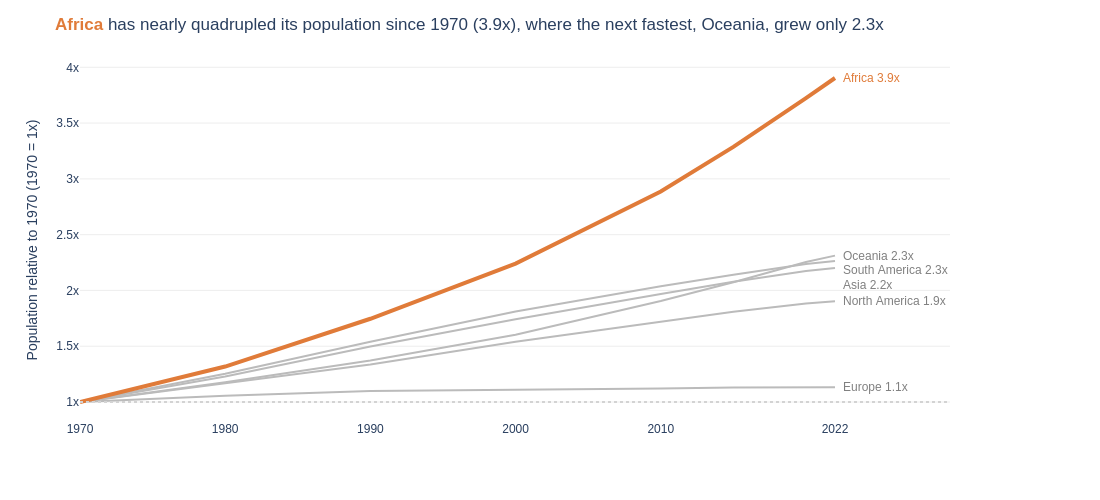

In [3]:
# Q1
cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
cont['Growth'] = cont['Population'] / cont.groupby('Continent')['Population'].transform('first')   # 1970 = 1x

last = cont.loc[cont['Year'] == 2022].sort_values('Growth', ascending=False)
fastest, runner = last.iloc[0], last.iloc[1]

colors = {c: (ORANGE if c == fastest['Continent'] else GREY) for c in cont['Continent'].unique()}

fig = px.line(cont, x='Year', y='Growth', color='Continent', color_discrete_map=colors,
              category_orders={'Continent': last['Continent'].tolist()[::-1]},   # highlighted line drawn last = on top
              template='plotly_white', height=500,
              hover_data={'Growth': ':.2f', 'Population': ':,'})
fig.update_traces(line=dict(width=2))
fig.update_traces(line=dict(width=4), selector=dict(name=fastest['Continent']))

# Direct labels at the end of each line (nudged apart so they don't overlap)
label_y = last['Growth'].tolist()
for i in range(1, len(label_y)):
    label_y[i] = min(label_y[i], label_y[i - 1] - 0.13)
for (_, row), ly in zip(last.iterrows(), label_y):
    is_top = row['Continent'] == fastest['Continent']
    fig.add_annotation(x=2022, y=ly, text=f"{row['Continent']} {row['Growth']:.1f}x", showarrow=False,
                       xanchor='left', xshift=6, font=dict(color=ORANGE if is_top else 'grey', size=12))

fig.add_hline(y=1, line_dash='dot', line_color='lightgrey')   # 1x = no growth

fig.update_layout(
    title=(f"<span style='color:{ORANGE}'><b>{fastest['Continent']}</b></span> has nearly quadrupled its population "
           f"since 1970 ({fastest['Growth']:.1f}x), where the next fastest, {runner['Continent']}, grew only {runner['Growth']:.1f}x"),
    font=dict(family='Arial', size=12), showlegend=False, margin=dict(r=150),
    xaxis=dict(title='', showgrid=False, tickvals=[1970, 1980, 1990, 2000, 2010, 2022]),
    yaxis=dict(title='Population relative to 1970 (1970 = 1x)', ticksuffix='x', gridcolor='#EEEEEE'))
save_and_show(fig, 'q1_line')

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

This time, I chose a sorted horizontal bar chart because the question asks for a ranking as top 15. The human eye compares bar lengths much more accurately than it compares areas or colors. I prefered to go with the horizontal orientation because the country names are long, which allows the label to be read before the value. The bars are sorted by value and start from a zero baseline, which is a requirement for bar charts. The color carries meaning: African countries, where I am addressing the second part of the question, are orange; while the others are gray. This makes it possible to identify the count (4) at a single glance. I added direct labels at the end of each bar (with "M" representing "million") and removed the x-axis, as it would only create unnecessary clutter in this context.

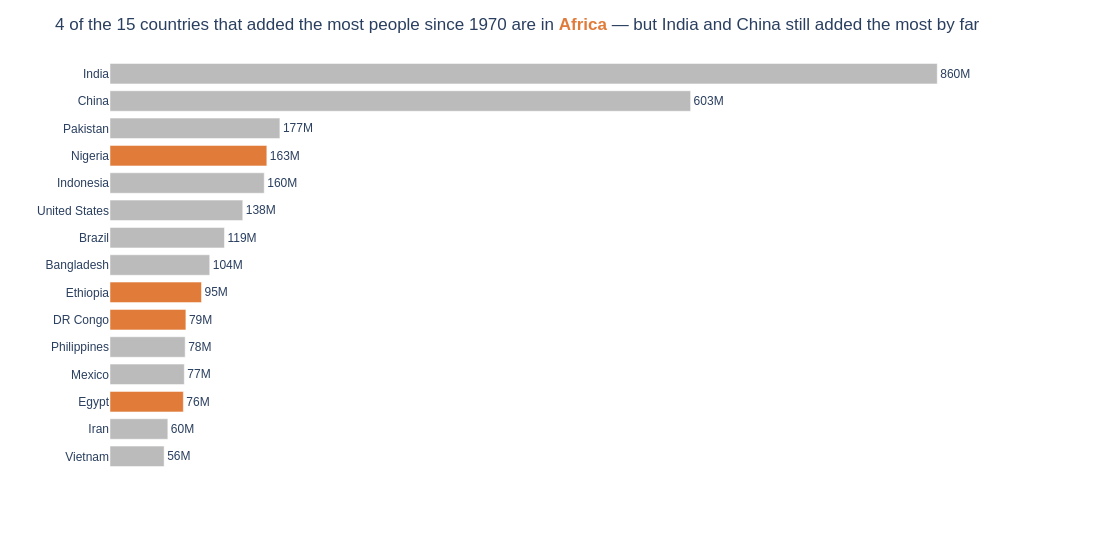

In [4]:
# Q2
df['Added'] = df['2022 Population'] - df['1970 Population']

top15 = df.nlargest(15, 'Added').sort_values('Added')     # ascending -> largest bar on top
n_africa = (top15['Continent'] == 'Africa').sum()
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other')
top15['Label'] = (top15['Added'] / 1e6).map('{:,.0f}M'.format)

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group', text='Label',
             color_discrete_map={'Africa': ORANGE, 'Other': GREY},
             hover_data={'Continent': True, 'Added': ':,', 'Group': False, 'Label': False},
             template='plotly_white', height=550)
fig.update_traces(textposition='outside', cliponaxis=False)

fig.update_layout(
    title=(f"{n_africa} of the 15 countries that added the most people since 1970 are in "
           f"<span style='color:{ORANGE}'><b>Africa</b></span> — but India and China still added the most by far"),
    font=dict(family='Arial', size=12), showlegend=False, bargap=0.25,
    xaxis=dict(visible=False, range=[0, top15['Added'].max() * 1.1]),   # zero baseline, labels replace the axis
    yaxis=dict(title='', categoryorder='total ascending'))
save_and_show(fig, 'q2_bar')

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

In this one, I decided to use a scatter plot. It's because the concern here is the relationship between two numerical variables, which are area and population. Since both area and population span several orders of magnitude, I used a logarithmic scale for both axes. Otherwise, most countries would cluster in the bottom-left corner, which would lead to overplotting. The dashed trend line (a log-log fit) serves as a reference: countries above the line are “overpopulated” relative to their size, while those below are “underpopulated.”

Color is used to highlight continents: Asian countries are blue (because on average they sit above the trend line), while those from South America and Oceania (which mostly sit below it) are pink; all others are shown in gray to provide context. This approach illustrates the differences without requiring six distinct colors. I annotated four countries with populations exceeding 10 million that deviate most significantly from the pattern (Bangladesh, India, Canada, and Australia) rather than labeling every single data point. Correlation does not mean causation, so the title simply says that the two variables increase together.

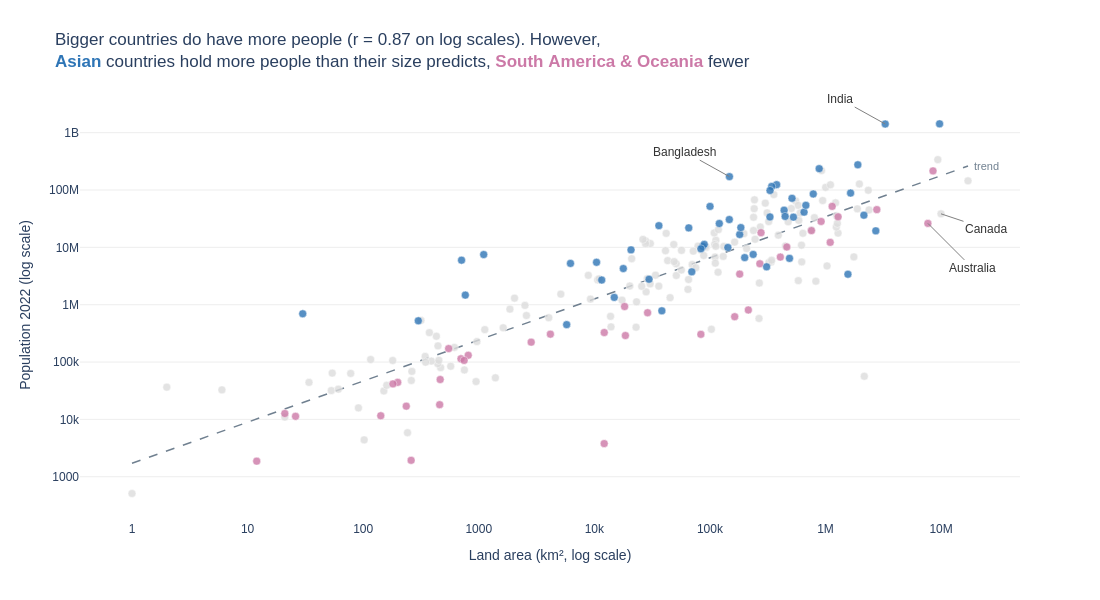

In [5]:
# Q3
d = df.copy()
d['logA'] = np.log10(d['Area'])
d['logP'] = np.log10(d['2022 Population'])
slope, intercept = np.polyfit(d['logA'], d['logP'], 1)          # trend on log-log scale
r = np.corrcoef(d['logA'], d['logP'])[0, 1]
d['Residual'] = d['logP'] - (intercept + slope * d['logA'])     # + above trend, - below

d['Group'] = d['Continent'].map({'Asia': 'Asia', 'South America': 'South America & Oceania',
                                 'Oceania': 'South America & Oceania'}).fillna('Other')

fig = px.scatter(d, x='Area', y='2022 Population', color='Group',
                 color_discrete_map={'Asia': BLUE, 'South America & Oceania': PINK, 'Other': LGREY},
                 category_orders={'Group': ['Other', 'South America & Oceania', 'Asia']},   # accents drawn on top
                 log_x=True, log_y=True, hover_name='Country', opacity=0.8,
                 hover_data={'Continent': True, 'Group': False, 'Area': ':,', '2022 Population': ':,'},
                 template='plotly_white', height=600)
fig.update_traces(marker=dict(size=8, line=dict(width=0.5, color='white')))

# Trend line, moved behind the points
xs = np.array([d['Area'].min(), d['Area'].max()])
fig.add_scatter(x=xs, y=10 ** (intercept + slope * np.log10(xs)), mode='lines',
                line=dict(color='slategrey', dash='dash', width=1.5), hoverinfo='skip', showlegend=False)
fig.data = fig.data[-1:] + fig.data[:-1]
fig.add_annotation(x=np.log10(xs[1]), y=intercept + slope * np.log10(xs[1]), text='trend', showarrow=False,
                   xanchor='left', xshift=4, font=dict(color='slategrey', size=11))

# Label the large countries that break the pattern most (annotation x/y on log axes = log10)
big = d.loc[d['2022 Population'] > 10_000_000]
outliers = pd.concat([big.nlargest(2, 'Residual'), big.nsmallest(2, 'Residual')])
for _, row in outliers.iterrows():
    above = row['Residual'] > 0
    fig.add_annotation(x=np.log10(row['Area']), y=np.log10(row['2022 Population']), text=row['Country'],
                       showarrow=True, arrowhead=0, arrowcolor='grey',
                       ax=-45 if above else 45, ay=-25 if above else (45 if row['Country'] == 'Australia' else 15),
                       font=dict(size=12, color='#333333'))

fig.update_layout(
    title=(f"Bigger countries do have more people (r = {r:.2f} on log scales). However,"
           f"<br><span style='color:{BLUE}'><b>Asian</b></span> countries hold more people than their size predicts, "
           f"<span style='color:{PINK}'><b>South America & Oceania</b></span> fewer"),
    font=dict(family='Arial', size=12), showlegend=False, margin=dict(t=90),
    xaxis=dict(title='Land area (km², log scale)', showgrid=False),
    yaxis=dict(title='Population 2022 (log scale)', gridcolor='#EEEEEE'))
save_and_show(fig, 'q3_scatter')

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

For this question, I chose a box plot to use because the question asks for the "spread, not just the average" and involves comparing multiple groups, as 6 continents. Here, the box plot provides us a compact representation of the median, IQR, and outliers. A histogram is better suited for a single distribution, while a violin plot would produce a misleading shape, given that some continents have very few countries (for instance, 14 in South America). The density is heavily right-skewed (ranging from 23,000/km² in Macau to 0.03/km² in Greenland), so I applied a log scale. Otherwise, all the boxes would have been compressed against zero.

The continents are ordered by their medians, and the chart is oriented horizontally because the continent names are long. Outliers—consisting of city-states and microstates—are displayed individually using `points='outliers'`.

The reference line represents the global median rather than the mean, as the median is a more accurate measure of central tendency for skewed data. I used a gray-and-highlight color scheme: Asia is colored blue (matching the color used for Asia in others as well) because it contains the world’s most densely populated areas as Macau, Singapore, Hong Kong and exhibits the widest absolute range. The other continents are shown in gray to provide context. In the title, the word "Asia" is colored to match the corresponding box.

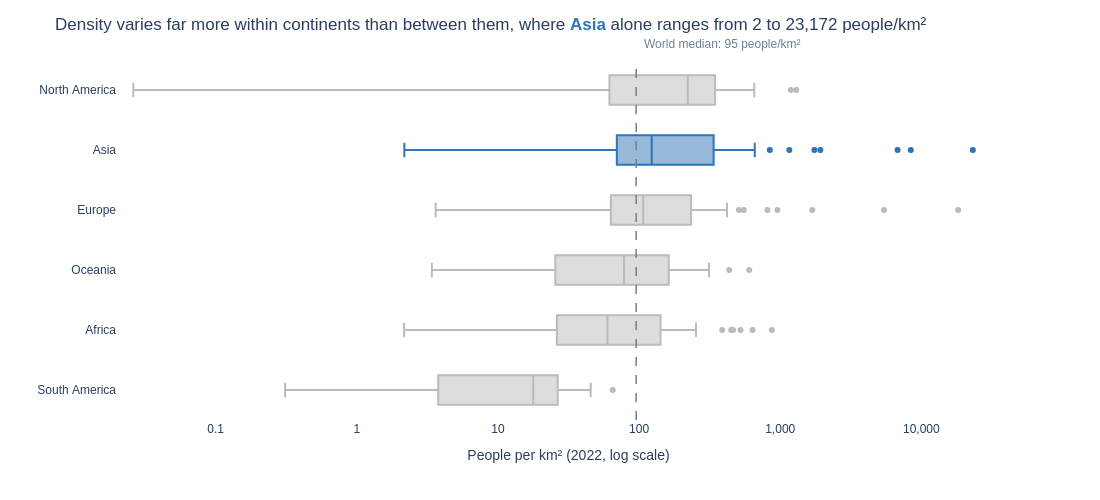

In [6]:
# Q4
order = df.groupby('Continent')['Density'].median().sort_values(ascending=False).index.tolist()
world_med = df['Density'].median()
asia = df.loc[df['Continent'] == 'Asia', 'Density']

fig = px.box(df, x='Density', y='Continent', color='Continent', orientation='h',
             points='outliers', log_x=True,
             category_orders={'Continent': order},           # sorted by median, highest on top
             color_discrete_map={c: (BLUE if c == 'Asia' else GREY) for c in order},   # grey + highlight
             hover_name='Country', template='plotly_white', height=500)

# Median reference line (median, not mean: density is heavily skewed)
fig.add_vline(x=world_med, line_dash='dash', line_color='slategrey', line_width=1.5)
fig.add_annotation(x=np.log10(world_med), y=1.02, xref='x', yref='paper',   # annotation x on a log axis = log10
                   text=f'World median: {world_med:.0f} people/km²', showarrow=False,
                   xanchor='left', xshift=6, yanchor='bottom', font=dict(color='slategrey', size=12))

fig.update_layout(
    title=(f"Density varies far more within continents than between them, where "
           f"<span style='color:{BLUE}'><b>Asia</b></span> alone ranges from {asia.min():.0f} to {asia.max():,.0f} people/km²"),
    font=dict(family='Arial', size=12),
    boxmode='overlay', showlegend=False,                 # one box per row, centred
    xaxis=dict(title='People per km² (2022, log scale)', showgrid=False,
               tickvals=[0.1, 1, 10, 100, 1000, 10000], ticktext=['0.1', '1', '10', '100', '1,000', '10,000'],
               range=[np.log10(0.02), np.log10(50000)]),   # log axis range is given in log10 units
    yaxis=dict(title=''))
save_and_show(fig, 'q4_box')

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

Here, I went with a choropleth map because the question asks “where in the world” implying a focus on geographical patterns. A map is the most appropriate here (in my opinion) because the countries experiencing decline are adjacent to one another, forming a distinct cluster (in Eastern Europe). Since the data is bidirectional—representing like both growth(+) and decline(−), I thought that I should better use a diverging color scale like RdBu (It was also suggested in class), setting `color_continuous_midpoint=0` so that white represents “no change.” Red indicates decline, while blue indicates growth. This red-blue combination is CVD-safe (color vision deficiency friendly), unlike a red-green palette. To prevent extreme outliers, such as Qatar’s +317%, which is from skewing the entire color scale, I capped the range at ±60% and clearly indicated this in the colorbar (using ≤ / ≥). The exact values ​​can be viewed via hover tooltips. For the built-in geometry, I used `locations='CCA3'` and `locationmode='ISO-3'`. The term “Eastern Europe” in the title is styled in the same red color used on the map.

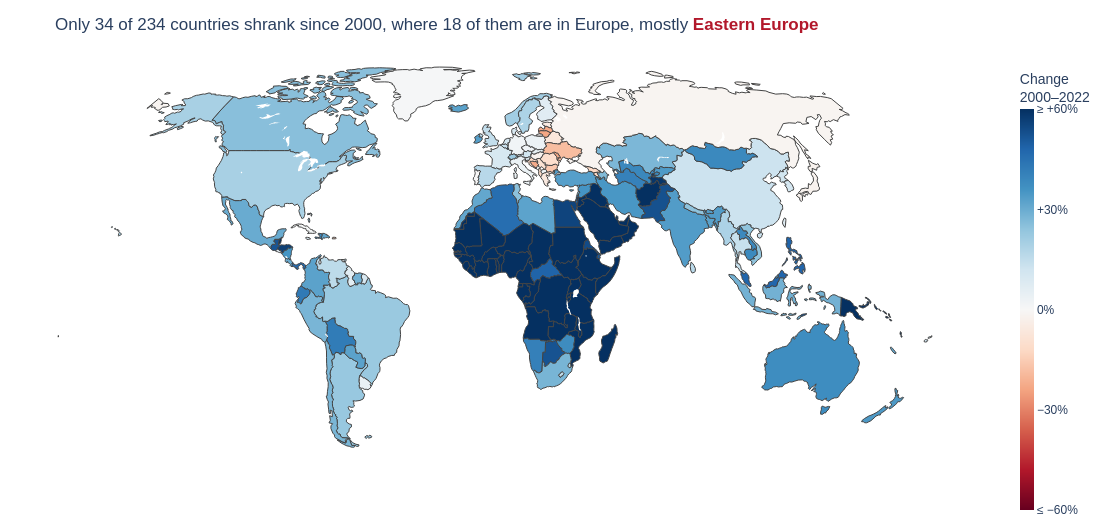

In [7]:
# Q5
df['Change_pct'] = (df['2022 Population'] / df['2000 Population'] - 1) * 100
n_shrank = (df['Change_pct'] < 0).sum()
n_eur = ((df['Change_pct'] < 0) & (df['Continent'] == 'Europe')).sum()
CAP = 60   # colour scale capped at ±60% so extreme growth (Qatar +317%) doesn't wash out the rest

fig = px.choropleth(df, locations='CCA3', locationmode='ISO-3', color='Change_pct',
                    color_continuous_scale='RdBu',          # diverging: red = shrank, blue = grew
                    color_continuous_midpoint=0,            # white = no change
                    range_color=[-CAP, CAP],
                    hover_name='Country',
                    hover_data={'CCA3': False, 'Change_pct': ':+.1f', 'Continent': True},
                    labels={'Change_pct': 'Change 2000–2022 (%)'},
                    template='plotly_white', height=520)

fig.update_layout(
    title=(f"Only {n_shrank} of {len(df)} countries shrank since 2000, where {n_eur} of them are in Europe, mostly "
           f"<span style='color:#B2182B'><b>Eastern Europe</b></span>"),
    font=dict(family='Arial', size=12),
    geo=dict(showframe=False, showcoastlines=False, projection_type='natural earth'),
    margin=dict(l=0, r=0, t=60, b=0),
    coloraxis_colorbar=dict(title='Change<br>2000–2022', thickness=14,
                            tickvals=[-60, -30, 0, 30, 60],
                            ticktext=['≤ −60%', '−30%', '0%', '+30%', '≥ +60%'])   # cap disclosed
)
save_and_show(fig, 'q5_choropleth')

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

Here, I chose a treemap because the question involves a part-to-whole relationship with a two-level hierarchy like continent to country, and it requires both to be represented in a single figure. Since population is an additive value, the areas at each level are meaningful, where a continent box represents the sum of the countries it contains. I established a single root using `px.Constant('World')`. The labels display the name, followed by the value in millions/billions, and then the share of the global total (%). As I mentioned on the previous ones; colors are meaningful and consistent throughout the notebook: Asia, which accounts for the majority of the world's population, is blue (matching the color used for Asia in Q3 and Q4), while Africa (the fastest-growing continent) is orange. Other continents are rendered in a neutral gray, with parent nodes appearing in a lighter shade of gray. In this way, the chart links the narrative of Africa’s growth to its current share of the global population. The colored words in the title correspond to the boxes, effectively serving as a legend.

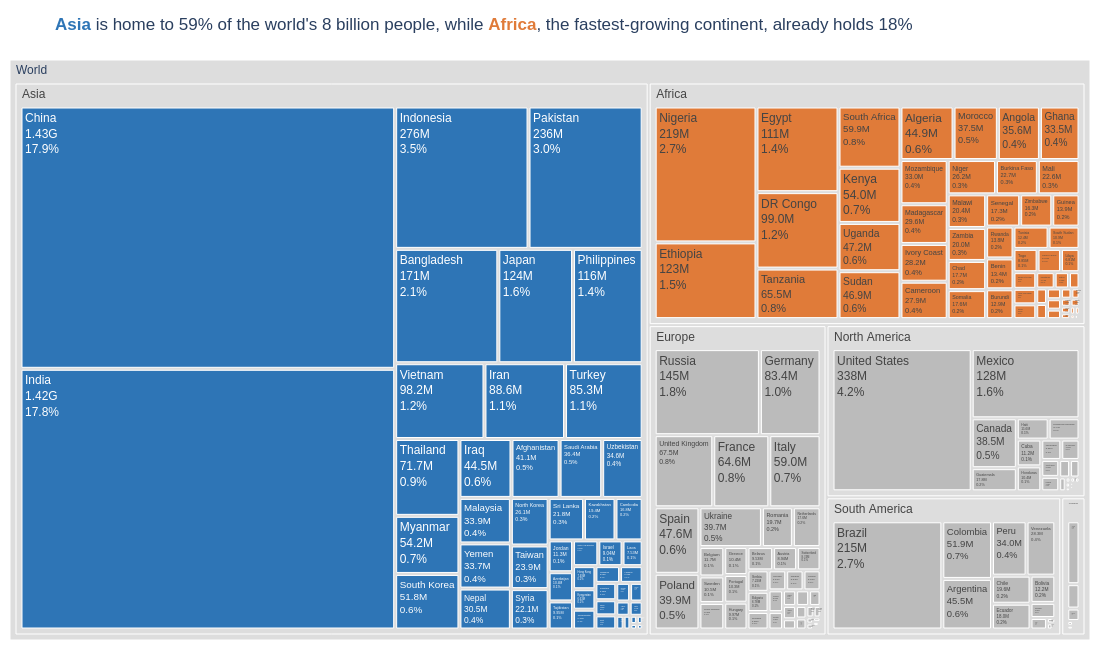

In [8]:
# Q6
world_total = df['2022 Population'].sum()
asia_share = df.loc[df['Continent'] == 'Asia', '2022 Population'].sum() / world_total
africa_share = df.loc[df['Continent'] == 'Africa', '2022 Population'].sum() / world_total

fig = px.treemap(df, path=[px.Constant('World'), 'Continent', 'Country'],   # root -> continent -> country
                 values='2022 Population',                                    # additive -> areas meaningful
                 template='plotly_white', height=650)

fig.update_traces(
    texttemplate='%{label}<br>%{value:.3s}<br>%{percentRoot:.1%}',   # label, value, share of world
    hovertemplate='<b>%{label}</b><br>%{value:,.0f}<br>%{percentRoot:.1%} of world<extra></extra>',
    root_color='white')

# Asia blue, Africa orange (same as the others), other countries grey,
# World + continent boxes are light grey
fig.data[0].marker.colors = [
    BLUE if parent == 'World/Asia' else
    ORANGE if parent == 'World/Africa' else
    (LGREY if label == 'World' or parent == 'World' else GREY)
    for label, parent in zip(fig.data[0].labels, fig.data[0].parents)]

fig.update_layout(
    title=(f"<span style='color:{BLUE}'><b>Asia</b></span> is home to {asia_share:.0%} of the world's "
           f"{world_total/1e9:.0f} billion people, while <span style='color:{ORANGE}'><b>Africa</b></span>, "
           f"the fastest-growing continent, already holds {africa_share:.0%}"),
    font=dict(family='Arial', size=12), margin=dict(t=60, l=10, r=10, b=10))
save_and_show(fig, 'q6_treemap')

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

Lastly, my selection for this one is a 100% stacked bar chart. Because the concern here is: how the whole is divided each year,rather than absolute numbers. Since each bar represents 100%, the shares can be compared directly across years.

There are two sides to the story: Africa is rising, while Europe is declining. Africa is positioned at the baseline (at the bottom), and Europe is at the top (anchored to the 100% line). This ensures that both highlighted segments have a fixed edge, allowing for an accurate comparison of their lengths, while the segments in between are left to "float." Africa is colored orange (consistent with its color throughout the notebook). Europe is dark gray, serving as a secondary highlight, where Africa’s rise is the primary narrative, and Europe’s decline is its counterpart. The dark gray makes Europe visible without competing with the orange (following a visual hierarchy: the primary highlight is colored, the secondary highlight is dark gray, and the context is light gray).

Furthermore, I wanted to avoid adding an additional color here. Asia and the rest of the world are rendered in light gray as context. Percentage labels are included only for the Africa and Europe segments. A legend is provided to help distinguish between the different shades of gray. Because the years are not equally spaced (2015, 2020, 2022), the x-axis is set to a categorical scale. The colored words in the title correspond to the respective segments.

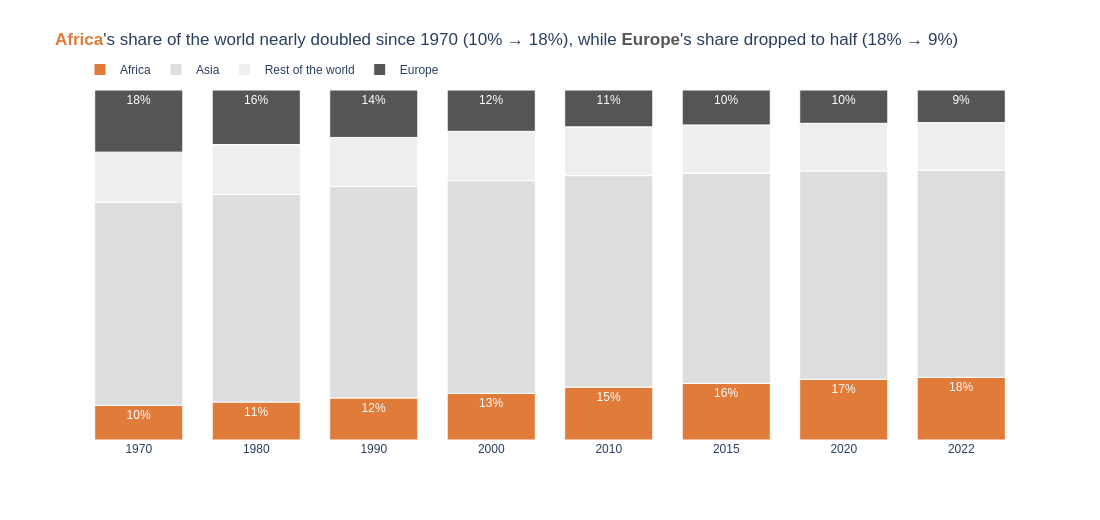

In [9]:
# Q7
keep = ['Africa', 'Asia', 'Europe']
q7 = df_long.assign(Group=df_long['Continent'].where(df_long['Continent'].isin(keep), 'Rest of the world'))
q7 = q7.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
q7['Share'] = q7['Population'] / q7.groupby('Year')['Population'].transform('sum')   # each year sums to 100%
q7['Label'] = np.where(q7['Group'].isin(['Africa', 'Europe']), q7['Share'].map('{:.0%}'.format), '')
q7['Year'] = q7['Year'].astype(str)          # uneven years -> categorical axis
sh = q7.set_index(['Group', 'Year'])['Share']

fig = px.bar(q7, x='Year', y='Share', color='Group', text='Label',
             color_discrete_map={'Africa': ORANGE, 'Asia': LGREY, 'Rest of the world': '#EEEEEE', 'Europe': DARK},
             category_orders={'Group': ['Africa', 'Asia', 'Rest of the world', 'Europe']},   # Africa on the baseline, Europe on top
             hover_data={'Share': ':.1%', 'Population': ':,', 'Label': False},
             template='plotly_white', height=520)
fig.update_traces(textposition='inside', textfont=dict(color='white', size=12),
                  marker_line_color='white', marker_line_width=1)

fig.update_layout(
    title=(f"<span style='color:{ORANGE}'><b>Africa</b></span>'s share of the world nearly doubled since 1970 "
           f"({sh['Africa','1970']:.0%} → {sh['Africa','2022']:.0%}), while "
           f"<span style='color:{DARK}'><b>Europe</b></span>'s share dropped to half ({sh['Europe','1970']:.0%} → {sh['Europe','2022']:.0%})"),
    font=dict(family='Arial', size=12), bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.1, title=''), margin=dict(t=90),
    xaxis=dict(title='', type='category'),
    yaxis=dict(visible=False, range=[0, 1]))
save_and_show(fig, 'q7_stacked_bar')

In [10]:
!zip -r images.zip images

  adding: images/ (stored 0%)
  adding: images/q1_line.png (deflated 19%)
  adding: images/q6_treemap.png (deflated 8%)
  adding: images/q7_stacked_bar.png (deflated 40%)
  adding: images/q4_box.png (deflated 28%)
  adding: images/q5_choropleth.png (deflated 7%)
  adding: images/q2_bar.png (deflated 29%)
  adding: images/q3_scatter.png (deflated 16%)
